# UTS: Penambangan Data
## Rancangan Classification Lonjakan Deteksi Hotspot MODIS dengan Clustering Pendukung
**Muhammad Aziz Syah Dani, F1E325063,  Informatika R-002**  
Fakultas Sains dan Teknologi, Universitas Jambi.  
Dosen: Ulfa Khaira S.Komp, M.Kom; Akhiyar Waladi S.Komp. 

UTS (Ujian Tengah Semester) 2026/2027.

### 1. Konfigurasi
**Apa:** Memeriksa dependensi dan file lokal.

**Mengapa:** Menjaga eksekusi tanpa unduhan otomatis.

**Cara membaca:** Missing package harus diselesaikan dengan requirements, bukan data contoh.

In [29]:
from pathlib import Path
import importlib.util, time

required = ['numpy', 'pandas', 'scipy', 'sklearn', 'matplotlib', 'shapely']
missing = [x for x in required if importlib.util.find_spec(x) is None]
if missing:
    raise RuntimeError('Paket belum tersedia: ' + ', '.join(missing))
BASE = Path.cwd()  # Colab: Path('/content/Nama zip yang kita masukkin nanti, izin pak.')
for r in [
    'checkpoint_sha256.json',
    'hasil/data_sesudah_diolah.csv',
    'sources/st_dbscan_upstream.py',
]:
    assert (BASE / r).is_file(), r
START = time.monotonic()
print('Seed 42; seluruh input lokal.')

Seed 42; seluruh input lokal.


### 2. Fungsi audit dan algoritma
**Apa:** Mendefinisikan seluruh fungsi.

**Mengapa:** Kode dapat ditelusuri.

**Cara membaca:** Varian dua ambang Cakmak/Plank; seluruh density factor Birant–Kut tidak diklaim diimplementasikan.

In [30]:
"""ST-DBSCAN dua ambang, audit ulang, dan gerbang classification; raw read-only."""

from pathlib import Path
import json, io, hashlib, zipfile, time, platform, importlib.util, importlib.metadata as meta
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.cluster import DBSCAN
from sklearn.neighbors import BallTree
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.metrics.pairwise import haversine_distances

SEED = 42
R_KM = 6371.0088
PRIMARY = (2.0, 48.0, 5)
CUTOFF = pd.Timestamp('2026-10-30 23:59:59', tz='UTC')
GRID = [
    (s, t, m) for s in (1.0, 2.0, 5.0) for t in (24.0, 48.0, 72.0) for m in (3, 5, 10)
]


def sha(p):
    h = hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda: f.read(1048576), b''):
            h.update(b)
    return h.hexdigest()


def save_json(p, obj):
    Path(p).write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str))


def audit_again(base):
    base = Path(base)
    out = base / 'clustering'
    out.mkdir(exist_ok=True)
    protocol = out / 'protokol_sebelum_eksperimen.json'
    if not protocol.exists():
        save_json(
            protocol,
            dict(
                primary=PRIMARY,
                sensitivity_grid=GRID,
                seed=SEED,
                partition='tahun UTC dan version literal',
                metric='haversine and absolute UTC hours',
                scope='all valid retained detections; not confirmed vegetation fires',
                rationale='2 km beberapa piksel nominal; 48 jam lintasan berulang; 5 rekaman termasuk diri; eksploratif',
                recovery_note='Parameter dipertahankan dari eksperimen sesi sebelumnya; berkas dipulihkan dengan eksekusi ulang, bukan pemilihan ulang berdasarkan hasil',
                created_utc=datetime.now(timezone.utc).isoformat(),
            ),
        )
    for rel, digest in json.loads(
        (base / 'checkpoint_sha256.json').read_text()
    ).items():
        assert sha(base / rel) == digest, rel
    raw = base / 'dataset yang di gunakan/NASA_MODIS_2015_2026_RAW.zip'
    expected = json.loads((base / 'hasil/audit_ringkas.json').read_text())
    assert sha(raw) == expected['zip_sha256']
    old = pd.read_csv(base / 'hasil/manifest_sumber.csv', dtype=str).set_index(
        'source_file'
    )
    rows = []
    allkeys = []
    with zipfile.ZipFile(raw) as z:
        assert z.testzip() is None
        for n in sorted(n for n in z.namelist() if n.lower().endswith('.csv')):
            b = z.read(n)
            a = pd.read_csv(io.BytesIO(b), dtype=str, keep_default_na=False)
            h = hashlib.sha256(b).hexdigest()
            assert h == old.loc[Path(n).name, 'sha256'] and len(a) == int(
                old.loc[Path(n).name, 'rows']
            )
            ts = pd.to_datetime(
                a.acq_date + ' ' + a.acq_time.str.zfill(4),
                format='%Y-%m-%d %H%M',
                utc=True,
            )
            key = pd.DataFrame(
                dict(
                    latitude=pd.to_numeric(a.latitude),
                    longitude=pd.to_numeric(a.longitude),
                    time=ts,
                    satellite=a.satellite,
                    instrument=a.instrument,
                    source_file=n,
                )
            )
            allkeys.append(key)
            rows.append(
                dict(
                    source_file=n,
                    sha256=h,
                    hash_match_previous=True,
                    rows=len(a),
                    exact_duplicates_within_file=int(a.duplicated().sum()),
                    date_min=str(ts.min()),
                    date_max=str(ts.max()),
                    versions_literal=json.dumps(a.version.value_counts().to_dict()),
                    nrt_documented_rows=int(a.version.eq('6.1NRT').sum()),
                    standard_documented_code_rows=int(a.version.eq('6.03').sum()),
                    archive_unresolved_6103_rows=int(a.version.eq('61.03').sum()),
                    original_download_url='BELUM_DIBERIKAN',
                    original_access_time='BELUM_DIBERIKAN',
                )
            )
    pd.DataFrame(rows).to_csv(out / 'audit_ulang_13_csv.csv', index=False)
    keys = pd.concat(allkeys, ignore_index=True)
    dup = keys.duplicated(
        ['latitude', 'longitude', 'time', 'satellite', 'instrument'], keep=False
    )
    keys.loc[dup].to_csv(out / 'duplikasi_kunci_audit_ulang.csv', index=False)
    d = pd.read_csv(
        base / 'hasil/data_sesudah_diolah.csv',
        dtype={'version': str, 'type': str},
        low_memory=False,
    )
    d['acq_datetime_utc'] = pd.to_datetime(d.acq_datetime_utc, utc=True)
    assert (
        len(d) == 154184 and d.row_id.is_unique and d.acq_datetime_utc.max() <= CUTOFF
    )
    d = d.sort_values(['year', 'version', 'acq_datetime_utc', 'row_id']).reset_index(
        drop=True
    )
    d['partition'] = d.year.astype(str) + '__' + d.version
    d['boundary_near_72h'] = False
    for _, g in d.groupby('partition'):
        y = int(g.year.iloc[0])
        v = g.version.iloc[0]
        lo = pd.Timestamp(f'{y}-01-01', tz='UTC')
        hi = min(
            pd.Timestamp(f'{y+1}-01-01', tz='UTC'), CUTOFF + pd.Timedelta(seconds=1)
        )
        if y == 2026 and v == '61.03':
            hi = pd.Timestamp('2026-09-01', tz='UTC')
        if y == 2026 and v == '6.1NRT':
            lo = pd.Timestamp('2026-09-01', tz='UTC')
        d.loc[g.index, 'boundary_near_72h'] = (
            (g.acq_datetime_utc - lo).dt.total_seconds() <= 259200
        ) | ((hi - g.acq_datetime_utc).dt.total_seconds() <= 259200)
    save_json(
        out / 'audit_ulang_ringkas.json',
        dict(
            csv_count=len(rows),
            raw_rows=len(keys),
            exact_key_duplicates=int(dup.sum()),
            unchanged_raw=True,
            raw_zip_sha256=sha(raw),
            retained_detections=len(d),
            processed_csv_sha256=sha(base / 'hasil/data_sesudah_diolah.csv'),
            unresolved_version='61.03',
            access_utc=datetime.now(timezone.utc).isoformat(),
        ),
    )
    return d


def build_edges(g, max_space=5.0, max_hours=72.0):
    xy = np.radians(g[['latitude', 'longitude']].to_numpy(float))
    hours = g.acq_datetime_utc.astype('int64').to_numpy() / 3.6e12
    tree = BallTree(xy, metric='haversine')
    rr = []
    cc = []
    ss = []
    tt = []
    for start in range(0, len(g), 256):
        ind, dist = tree.query_radius(
            xy[start : start + 256], r=max_space / R_KM, return_distance=True
        )
        for off, (js, dd) in enumerate(zip(ind, dist)):
            i = start + off
            dt = np.abs(hours[js] - hours[i])
            ok = dt <= max_hours
            rr.append(np.full(ok.sum(), i, dtype=np.int32))
            cc.append(js[ok].astype(np.int32))
            ss.append(dd[ok] * R_KM)
            tt.append(dt[ok])
    return tuple(np.concatenate(x) for x in (rr, cc, ss, tt))


def fit_edges(n, edges, s, t, m):
    row, col, space, hours = edges
    ok = (space <= s) & (hours <= t)
    graph = csr_matrix((np.ones(ok.sum()), (row[ok], col[ok])), shape=(n, n))
    graph.sort_indices()
    assert np.all(graph.diagonal() == 1)
    fit = DBSCAN(eps=1.0, min_samples=m, metric='precomputed', n_jobs=1).fit(graph)
    core = np.zeros(n, bool)
    core[fit.core_sample_indices_] = True
    return fit.labels_, core, graph


def params(s, t, m):
    return f's{int(s)}_h{int(t)}_m{m}'


def run_clustering(base, d):
    out = Path(base) / 'clustering'
    start = time.monotonic()
    configs = [PRIMARY] + [p for p in GRID if p != PRIMARY]
    labelsall = {params(*p): np.full(len(d), -1, dtype=np.int32) for p in configs}
    offsets = {k: 0 for k in labelsall}
    coreall = np.zeros(len(d), bool)
    rows = []
    sils = []
    silrows = []
    qualities = []
    for part, g0 in d.groupby('partition', sort=True):
        ids = g0.index.to_numpy()
        g = g0.reset_index(drop=True)
        edges = build_edges(g)
        for s, t, m in configs:
            label, core, graph = fit_edges(len(g), edges, s, t, m)
            key = params(s, t, m)
            ncl = int(label.max() + 1)
            yes = label >= 0
            global_l = label.copy()
            global_l[yes] += offsets[key]
            offsets[key] += ncl
            labelsall[key][ids] = global_l
            durations = (
                g.assign(label=label)
                .loc[yes]
                .groupby('label')
                .acq_datetime_utc.agg(['min', 'max'])
            )
            days = (durations['max'] - durations['min']).dt.total_seconds() / 86400
            sizes = np.bincount(label[yes]) if yes.any() else np.array([0])
            rows.append(
                dict(
                    partition=part,
                    config=key,
                    eps_spatial_km=s,
                    eps_temporal_hours=t,
                    min_samples=m,
                    n=len(g),
                    clusters=ncl,
                    noise=int((~yes).sum()),
                    core=int(core.sum()),
                    border=int((yes & ~core).sum()),
                    largest_cluster=int(sizes.max()),
                    max_duration_days=float(days.max()) if len(days) else 0.0,
                )
            )
            if (s, t, m) == PRIMARY:
                primary_label = label.copy()
                coreall[ids] = core
        valid = np.flatnonzero(primary_label >= 0)
        pick = np.sort(
            np.random.default_rng(SEED).choice(
                valid, min(1500, len(valid)), replace=False
            )
        )
        score = None
        if 2 <= len(np.unique(primary_label[pick])) < len(pick):
            xy = np.radians(g.loc[pick, ['latitude', 'longitude']].to_numpy())
            h = g.loc[pick, 'acq_datetime_utc'].astype('int64').to_numpy() / 3.6e12
            dist = np.maximum(
                haversine_distances(xy) * R_KM / PRIMARY[0],
                np.abs(h[:, None] - h[None, :]) / PRIMARY[1],
            )
            np.fill_diagonal(dist, 0)
            score = float(
                silhouette_score(dist, primary_label[pick], metric='precomputed')
            )
        sils.append(
            dict(
                partition=part,
                nonnoise_n=len(valid),
                sample_n=len(pick),
                silhouette=score,
                seed=SEED,
            )
        )
        silrows.extend([{'partition': part, 'row_id': g.row_id.iloc[i]} for i in pick])
        filters = {
            'confidence_ge30': g.confidence >= 30,
            'confidence_ge80': g.confidence >= 80,
            'Terra_only': g.satellite.eq('Terra'),
            'Aqua_only': g.satellite.eq('Aqua'),
        }
        if g.type.notna().any():
            filters['type0_only'] = g.type.eq('0')
        for name, mask in filters.items():
            ix = np.flatnonzero(mask.to_numpy())
            q = g.iloc[ix].reset_index(drop=True)
            if len(q):
                ll, _, _ = fit_edges(len(q), build_edges(q), *PRIMARY)
                yes = ll >= 0
                sizes = np.bincount(ll[yes]) if yes.any() else np.array([0])
                qualities.append(
                    dict(
                        partition=part,
                        scenario=name,
                        n=len(q),
                        clusters=int(ll.max() + 1),
                        noise=int((~yes).sum()),
                        largest_cluster=int(sizes.max()),
                        ARI_primary_on_same_rows=float(
                            adjusted_rand_score(primary_label[ix], ll)
                        ),
                    )
                )
    primary = labelsall[params(*PRIMARY)]
    result = d.copy()
    result['cluster_label'] = primary
    result['cluster_id'] = np.where(
        primary < 0, 'NOISE', [f'ST{x:05d}' for x in primary]
    )
    result['point_role'] = np.where(
        primary < 0, 'noise', np.where(coreall, 'core', 'border')
    )
    result.to_csv(out / 'hasil_st_dbscan.csv', index=False)
    pd.DataFrame({'row_id': d.row_id, **labelsall}).to_csv(
        out / 'keanggotaan_27_skenario.csv', index=False
    )
    per = pd.DataFrame(rows)
    per.to_csv(out / 'sensitivitas_per_strata.csv', index=False)
    base_rows = per[per.config.eq(params(*PRIMARY))].copy()
    base_rows['noise_percent'] = base_rows.noise / base_rows.n * 100
    base_rows.to_csv(out / 'hasil_utama_per_strata.csv', index=False)
    totals = []
    for s, t, m in configs:
        key = params(s, t, m)
        a = per[per.config.eq(key)]
        ll = labelsall[key]
        both = (primary >= 0) & (ll >= 0)
        totals.append(
            dict(
                config=key,
                eps_spatial_km=s,
                eps_temporal_hours=t,
                min_samples=m,
                **{
                    k: int(a[k].sum())
                    for k in ['n', 'clusters', 'noise', 'core', 'border']
                },
                largest_cluster=int(a.largest_cluster.max()),
                max_duration_days=float(a.max_duration_days.max()),
                noise_percent=float((ll < 0).mean() * 100),
                ARI_including_noise=float(adjusted_rand_score(primary, ll)),
                ARI_common_nonnoise=(
                    float(adjusted_rand_score(primary[both], ll[both]))
                    if both.any()
                    else None
                ),
                common_nonnoise_n=int(both.sum()),
            )
        )
    sensitivity = pd.DataFrame(totals)
    sensitivity.to_csv(out / 'sensitivitas_27_skenario.csv', index=False)
    summary = []
    for cluster, g in result[result.cluster_label >= 0].groupby(
        'cluster_id', sort=True
    ):
        lat = g.latitude.mean()
        lon = g.longitude.mean()
        radius = (
            haversine_distances(
                np.radians([[lat, lon]]),
                np.radians(g[['latitude', 'longitude']].to_numpy()),
            )[0]
            * R_KM
        )
        a = dict(
            cluster_id=cluster,
            partition=g.partition.iloc[0],
            detections=len(g),
            start_utc=str(g.acq_datetime_utc.min()),
            end_utc=str(g.acq_datetime_utc.max()),
            duration_days=(
                g.acq_datetime_utc.max() - g.acq_datetime_utc.min()
            ).total_seconds()
            / 86400,
            centroid_latitude=lat,
            centroid_longitude=lon,
            max_radius_km=radius.max(),
            dominant_province=g.province.mode().iloc[0],
            provinces=';'.join(sorted(g.province.unique())),
            confidence_mean=g.confidence.mean(),
            frp_mean_MW=g.frp.mean(),
            frp_max_MW=g.frp.max(),
            near_boundary_n=int(g.boundary_near_72h.sum()),
        )
        a.update({f'type_{v}': int(g.type.eq(str(v)).sum()) for v in range(4)})
        a['type_unknown'] = int(g.type.isna().sum())
        summary.append(a)
    summary = pd.DataFrame(summary)
    summary.to_csv(out / 'ringkasan_klaster.csv', index=False)
    summary.nlargest(15, 'detections').to_csv(
        out / 'klaster_terbesar_15.csv', index=False
    )
    pd.DataFrame(qualities).to_csv(
        out / 'sensitivitas_kualitas_satelit_type.csv', index=False
    )
    pd.DataFrame(sils).to_csv(out / 'silhouette_diagnostik.csv', index=False)
    pd.DataFrame(silrows).to_csv(out / 'row_id_sampel_silhouette.csv', index=False)
    result.groupby(['year', 'version', 'province', 'point_role']).size().rename(
        'detections'
    ).reset_index().to_csv(out / 'keanggotaan_per_wilayah.csv', index=False)
    save_json(
        out / 'ringkasan_eksperimen.json',
        dict(
            n=len(d),
            clusters=len(summary),
            noise=int((primary < 0).sum()),
            noise_percent=float((primary < 0).mean() * 100),
            core=int(coreall.sum()),
            border=int(((primary >= 0) & ~coreall).sum()),
            largest_cluster=int(summary.detections.max()),
            max_duration_days=float(summary.duration_days.max()),
            strata=len(base_rows),
            configurations=len(configs),
            elapsed_seconds=round(time.monotonic() - start, 2),
            classification_model_fitted=False,
        ),
    )
    return result, summary, sensitivity


def validate_implementation(base, d):
    base = Path(base)
    out = base / 'clustering'
    pool = d[(d.year == 2015) & (d.month == 9)].copy()
    center = pool[['latitude', 'longitude']].median().to_numpy()
    distance = haversine_distances(
        np.radians([center]), np.radians(pool[['latitude', 'longitude']].to_numpy())
    )[0]
    g = (
        pool.iloc[np.argsort(distance, kind='stable')[:1000]]
        .sort_values(['acq_datetime_utc', 'row_id'])
        .reset_index(drop=True)
    )
    ll, core, graph = fit_edges(len(g), build_edges(g), *PRIMARY)
    xy = np.radians(g[['latitude', 'longitude']].to_numpy())
    h = g.acq_datetime_utc.astype('int64').to_numpy() / 3.6e12
    full = np.maximum(
        haversine_distances(xy) * R_KM / 2, np.abs(h[:, None] - h[None, :]) / 48
    )
    np.fill_diagonal(full, 0)
    dense = DBSCAN(eps=1, min_samples=5, metric='precomputed').fit(full)
    assert (
        adjusted_rand_score(ll, dense.labels_) == 1
        and np.array_equal(np.flatnonzero(core), np.sort(dense.core_sample_indices_))
        and (graph != graph.T).nnz == 0
    )
    upstream = base / 'sources/st_dbscan_upstream.py'
    spec = importlib.util.spec_from_file_location('reference_stdbscan', upstream)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    lat, lon = xy.T
    xyz = R_KM * np.column_stack(
        [np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)]
    )
    ref = mod.ST_DBSCAN(
        eps1=2 * R_KM * np.sin(2 / (2 * R_KM)),
        eps2=48,
        min_samples=5,
        metric='euclidean',
    ).fit(np.column_stack([h, xyz]))
    ari = float(adjusted_rand_score(ll, ref.labels))
    assert ari == 1
    order = np.random.default_rng(SEED).permutation(len(g))
    shuffled, _, _ = fit_edges(
        len(g), build_edges(g.iloc[order].reset_index(drop=True)), *PRIMARY
    )
    restored = np.empty(len(g), int)
    restored[order] = shuffled
    record = dict(
        actual_rows=len(g),
        dense_vs_sparse_ARI=1.0,
        upstream_reference_ARI=ari,
        core_indices_identical=True,
        symmetric_neighborhood=True,
        permuted_order_ARI=float(adjusted_rand_score(ll, restored)),
        permuted_order_core_ARI=float(adjusted_rand_score(ll[core], restored[core])),
        permuted_order_noise_membership_equal=bool(
            np.array_equal(ll < 0, restored < 0)
        ),
        cluster_count_in_sample=int(ll.max() + 1),
        synthetic_data_used=False,
        upstream_sha256=sha(upstream),
    )
    save_json(out / 'validasi_implementasi.json', record)
    g[['row_id', 'latitude', 'longitude', 'acq_datetime_utc']].to_csv(
        out / 'row_id_validasi_implementasi.csv', index=False
    )
    i = int(np.flatnonzero(core)[0])
    ix = np.flatnonzero(full[i] <= 1)[:10]
    ex = g.loc[ix, ['row_id', 'latitude', 'longitude', 'acq_datetime_utc']].copy()
    ex.insert(0, 'anchor_row_id', g.row_id.iloc[i])
    ex['distance_km'] = haversine_distances(xy[[i]], xy[ix])[0] * R_KM
    ex['time_difference_hours'] = abs(h[ix] - h[i])
    ex['anchor_total_neighbors_including_self'] = int((full[i] <= 1).sum())
    ex.to_csv(out / 'contoh_manual_tetangga_nyata.csv', index=False)
    return record


def classification_gate(base):
    base = Path(base)
    out = base / 'clustering'
    p = pd.read_csv(base / 'hasil/data_panel_wilayah_harian.csv')
    f = pd.read_csv(base / 'hasil/data_fitur.csv')
    f['date'] = pd.to_datetime(f.date, utc=True)
    f['target_date'] = pd.to_datetime(f.target_date, utc=True)

    def split(s):
        return np.select(
            [
                s.dt.year <= 2023,
                s.dt.year == 2024,
                s.dt.year == 2025,
                s.dt.year == 2026,
            ],
            ['train', 'validation', 'test_2025', 'case_2026'],
            default='outside',
        )

    f['origin_split'] = split(f.date)
    f['target_split'] = split(f.target_date)
    f['same_subset'] = f.origin_split.eq(f.target_split)
    f['target_within_cutoff'] = f.target_date.le(CUTOFF.normalize())
    f['calendar_lookback_30d'] = f.date.ge(pd.Timestamp('2015-01-30', tz='UTC'))
    f['candidate_time_eligible'] = (
        f.same_subset & f.target_within_cutoff & f.calendar_lookback_30d
    )
    f['eligible_for_supervised_learning'] = False
    f['y_surge'] = np.nan
    f.to_csv(out / 'calon_fitur_dengan_gate_temporal.csv', index=False)
    rows = []
    for key, g in f.groupby('target_split'):
        rows.append(
            dict(
                subset=key,
                calendar_rows=len(g),
                time_eligible_before_QA=int(g.candidate_time_eligible.sum()),
                complete_recorded_30d_feature=int(
                    g.count_trailing_30d_recorded.notna().sum()
                ),
                coverage_verified_rows=0,
                availability_verified_rows=0,
                eligible_labeled_rows=0,
                positive_class_count=None,
                negative_class_count=None,
                prevalence=None,
            )
        )
    pd.DataFrame(rows).to_csv(
        out / 'kelayakan_classification_per_split.csv', index=False
    )
    p.recorded_detection_count.dropna().describe(
        percentiles=[0.5, 0.8, 0.9, 0.95, 0.99]
    ).to_csv(out / 'distribusi_hitung_positif_bukan_target.csv')
    gate = dict(
        classification_feasible=False,
        reason_codes=[
            'QA_NOT_AVAILABLE',
            'AVAILABLE_AT_UNKNOWN',
            'PROVENANCE_UNRESOLVED',
        ],
        negative_labels_created=0,
        target_quantiles_fitted=False,
        model_fitted=False,
        test2025_evaluated=False,
        cluster_ids_used_as_features=False,
        cluster_noise_used_as_negative_labels=False,
        candidate_rows=len(p),
        region_days_without_records=int(p.recorded_detection_count.isna().sum()),
    )
    save_json(out / 'keputusan_classification.json', gate)
    versions = {'python': platform.python_version()}
    for name in [
        'numpy',
        'pandas',
        'scipy',
        'scikit-learn',
        'matplotlib',
        'shapely',
        'pyproj',
        'nbformat',
        'ipython',
        'xgboost',
        'shap',
    ]:
        try:
            versions[name] = meta.version(name)
        except meta.PackageNotFoundError:
            versions[name] = 'NOT_INSTALLED'
    save_json(out / 'versi_lingkungan_revisi.json', versions)
    return gate

### 3. Audit ulang
**Apa:** Membaca semua 13 CSV dan memeriksa hash/duplikasi.

**Mengapa:** Raw harus sama dengan audit terdahulu.

**Cara membaca:** Hash memastikan kesamaan byte; tidak mengautentikasi asal NASA. Version dipertahankan string.

In [31]:
d = audit_again(BASE)
display(pd.read_csv(BASE / 'clustering/audit_ulang_13_csv.csv'))
display(
    pd.Series(json.loads((BASE / 'clustering/audit_ulang_ringkas.json').read_text()))
)

/tmp/ipykernel_11834/3683915005.py:134: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pd.Timestamp(f'{y+1}-01-01', tz='UTC'), CUTOFF + pd.Timedelta(seconds=1)
/tmp/ipykernel_11834/3683915005.py:134: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pd.Timestamp(f'{y+1}-01-01', tz='UTC'), CUTOFF + pd.Timedelta(seconds=1)
/tmp/ipykernel_11834/3683915005.py:134: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pd.Timestamp(f'{y+1}-01-01', tz='UTC'), CUTOFF + pd.Timedelta(seconds=1)
/tmp/ipykerne

,source_file,sha256,hash_match_previous,rows,exact_duplicates_within_file,date_min,date_max,versions_literal,nrt_documented_rows,standard_documented_code_rows,archive_unresolved_6103_rows,original_download_url,original_access_time
0,fire_archive_M-C61_834980.csv,7928dfb49ee9019142e6fcf765df016531f5a7aca853d7...,True,179921,0,2015-01-01 02:39:00+00:00,2015-12-31 16:44:00+00:00,"{""6.03"": 179921}",0,179921,0,BELUM_DIBERIKAN,BELUM_DIBERIKAN
1,fire_archive_M-C61_834981.csv,20e9a45076c5c8e61e8df609cc402ca1f87a43c203fc92...,True,24866,0,2016-01-01 02:07:00+00:00,2016-12-31 15:37:00+00:00,"{""6.03"": 24866}",0,24866,0,BELUM_DIBERIKAN,BELUM_DIBERIKAN
2,fire_archive_M-C61_834982.csv,a6ffcafa3c48659013b196e2956f57ec6604e614fc390d...,True,18454,0,2017-01-01 02:21:00+00:00,2017-12-31 18:05:00+00:00,"{""6.03"": 18454}",0,18454,0,BELUM_DIBERIKAN,BELUM_DIBERIKAN
3,fire_archive_M-C61_834984.csv,4437eba38e93f82da8a2458dfc92dcdc194a2254e7f1e4...,True,39276,0,2018-01-01 01:49:00+00:00,2018-12-31 14:36:00+00:00,"{""6.03"": 39276}",0,39276,0,BELUM_DIBERIKAN,BELUM_DIBERIKAN
4,fire_archive_M-C61_834985.csv,bdf337ab6452f9dd140fefc8947db9206c06b8a2307c9a...,True,91936,0,2019-01-01 01:19:00+00:00,2019-12-31 17:00:00+00:00,"{""6.03"": 91936}",0,91936,0,BELUM_DIBERIKAN,BELUM_DIBERIKAN
5,fire_archive_M-C61_834986.csv,4b77d51f73ab76bd655747979868c7ca9046afe0b642b0...,True,16980,0,2020-01-01 02:28:00+00:00,2020-12-31 17:13:00+00:00,"{""6.03"": 16980}",0,16980,0,BELUM_DIBERIKAN,BELUM_DIBERIKAN
6,fire_archive_M-C61_834987.csv,df371a752d0afd9db78a7d7c89395cb491ad2030f1b383...,True,14479,0,2021-01-31 05:45:00+00:00,2021-12-31 04:20:00+00:00,"{""6.03"": 14479}",0,14479,0,BELUM_DIBERIKAN,BELUM_DIBERIKAN
7,fire_archive_M-C61_834988.csv,cb0eb866d2fd4e6eb1ebbcbc6f4051e643c00ce71b79a8...,True,11745,0,2022-01-03 01:50:00+00:00,2022-12-31 15:39:00+00:00,"{""6.03"": 11745}",0,11745,0,BELUM_DIBERIKAN,BELUM_DIBERIKAN
8,fire_archive_M-C61_834989.csv,9d0acc533a669e26c14eb879843ff45be8954250cb226c...,True,53128,0,2023-01-01 06:40:00+00:00,2023-12-31 18:14:00+00:00,"{""61.03"": 53128}",0,0,53128,BELUM_DIBERIKAN,BELUM_DIBERIKAN
9,fire_archive_M-C61_834990.csv,2ed945d1be40564b2b59e17d4a847606cf77722c1542b3...,True,23542,0,2024-01-01 02:14:00+00:00,2024-12-30 18:04:00+00:00,"{""61.03"": 23542}",0,0,23542,BELUM_DIBERIKAN,BELUM_DIBERIKAN


csv_count                                                              13
raw_rows                                                           630384
exact_key_duplicates                                                    0
unchanged_raw                                                        True
raw_zip_sha256          8749435dfb96884cb30db501ac35f556fd1104b35e023f...
retained_detections                                                154184
processed_csv_sha256    cf505d81d257a80d1a7f7c766fb74afd9a6f780c7fdd4f...
unresolved_version                                                  61.03
access_utc                               2026-11-08T11:31:03.555294+00:00
dtype: object

### 4. FireMask dan QA
**Apa:** Membaca log akses raster dan metadata yang tersedia.

**Mengapa:** Metadata katalog bukan raster QA.

**Cara membaca:** Lihat status HTTP aktual; belum ada raster nyata yang digunakan.

MOD14A1/MYD14A1 memiliki hingga delapan plane **harian**. Dates/DAYSOFYEAR menentukan tanggal; plane bisa hilang. FireMask 5=non-fire land, 7–9=fire, 4=cloud, 6=unknown, 0/1/2=unprocessed, 3=water. QA bit 0–1 water/coast/land/missing; bit 2 night/day. Komposit tidak sama dengan hitungan baris FIRMS atau bukti seluruh overpass lengkap. Helper decoder belum diuji pada HDF nyata.

In [32]:
display(
    pd.DataFrame(json.loads((BASE / 'sources/percobaan_akses_hdf.json').read_text()))
)

,granule,url,status,reason,access_utc
0,MOD14A1.A2026273.h27v09.061.2026286104424,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,401,Unauthorized,2026-11-01T07:15:05.806625+00:00
1,MYD14A1.A2026273.h27v09.061.2026286104723,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,401,Unauthorized,2026-11-01T07:15:20.470025+00:00


### 5. Gerbang classification
**Apa:** Memeriksa kalender, t/t+1, lookback dan label.

**Mengapa:** Tidak boleh menciptakan negatif dari hari tanpa rekaman.

**Cara membaca:** Semua kelas/prevalensi tetap NA; eligible=0 bukan jumlah kelas negatif.

In [33]:
gate = classification_gate(BASE)
display(pd.read_csv(BASE / 'clustering/kelayakan_classification_per_split.csv'))
display(pd.Series(gate))

,subset,calendar_rows,time_eligible_before_QA,complete_recorded_30d_feature,coverage_verified_rows,availability_verified_rows,eligible_labeled_rows,positive_class_count,negative_class_count,prevalence
0,case_2026,2432,2416,86,0,0,0,NaN,NaN,NaN
1,test_2025,2920,2912,0,0,0,0,NaN,NaN,NaN
2,train,26288,26056,296,0,0,0,NaN,NaN,NaN
3,validation,2928,2920,0,0,0,0,NaN,NaN,NaN


classification_feasible                                                              False
reason_codes                             [QA_NOT_AVAILABLE, AVAILABLE_AT_UNKNOWN, PROVE...
negative_labels_created                                                                  0
target_quantiles_fitted                                                              False
model_fitted                                                                         False
test2025_evaluated                                                                   False
cluster_ids_used_as_features                                                         False
cluster_noise_used_as_negative_labels                                                False
candidate_rows                                                                       34568
region_days_without_records                                                          23809
dtype: object

### 6. Protokol ST-DBSCAN
**Apa:** Membekukan dua ambang dan strata.

**Mengapa:** Parameter dapat dijelaskan dan sensitivitas tidak disembunyikan.

**Cara membaca:** Utama 2 km/48 jam/minimum 5 termasuk diri. Pilihan eksploratif, bukan optimum.

$$N(i)=\{j:d_s(i,j)\leq\varepsilon_s,\ |t_i-t_j|\leq\varepsilon_t,\ z_i=z_j\},\qquad core(i)\iff |N(i)|\geq m.$$
Strata z adalah tahun UTC dan version literal. Haversine memakai R=6371,0088 km. Grid 1/2/5 km × 24/48/72 jam × 3/5/10 = 27 konfigurasi. eps bukan diameter/durasi maksimum klaster. Semua confidence/type pada utama; filter diuji sebagai sensitivitas. Batas strata dapat memotong kelompok.

In [34]:
display(
    pd.Series(
        json.loads((BASE / 'clustering/protokol_sebelum_eksperimen.json').read_text())
    )
)

primary                                                [2.0, 48.0, 5]
sensitivity_grid    [[1.0, 24.0, 3], [1.0, 24.0, 5], [1.0, 24.0, 1...
seed                                                               42
partition                               tahun UTC dan version literal
metric                               haversine and absolute UTC hours
scope               all valid retained detections; not confirmed v...
rationale           2 km beberapa piksel nominal; 48 jam lintasan ...
recovery_note       Parameter dipertahankan dari eksperimen sesi s...
created_utc                          2026-11-01T07:14:34.085085+00:00
dtype: object

### 7. Validasi implementasi
**Apa:** Membandingkan graf jarang, matriks penuh dan kode upstream pada 1.000 baris nyata.

**Mengapa:** Kesalahan lingkungan tetangga akan mengubah hasil.

**Cara membaca:** ARI=1 berarti kesamaan partisi sampel, bukan akurasi kebakaran. Urutan dapat memengaruhi border.

In [35]:
v = validate_implementation(BASE, d)
display(pd.Series(v))

actual_rows                                                                           1000
dense_vs_sparse_ARI                                                                    1.0
upstream_reference_ARI                                                                 1.0
core_indices_identical                                                                True
symmetric_neighborhood                                                                True
permuted_order_ARI                                                                 0.99981
permuted_order_core_ARI                                                                1.0
permuted_order_noise_membership_equal                                                 True
cluster_count_in_sample                                                                 41
synthetic_data_used                                                                  False
upstream_sha256                          128639c9b3b326395ab9fb3eaadcf1042f3039276c5877...

### 8. Eksekusi ST-DBSCAN
**Apa:** Menjalankan semua konfigurasi dan sensitivitas input.

**Mengapa:** Jumlah klaster/noise harus berasal dari eksekusi.

**Cara membaca:** Noise bukan data salah atau non-fire. Tidak ada fit classifier.

In [36]:
result, clusters, sensitivity = run_clustering(BASE, d)
display(
    pd.Series(json.loads((BASE / 'clustering/ringkasan_eksperimen.json').read_text()))
)
display(pd.read_csv(BASE / 'clustering/hasil_utama_per_strata.csv'))

n                                 154184
clusters                            3678
noise                              74383
noise_percent                  48.243008
core                               73129
border                              6672
largest_cluster                     4478
max_duration_days              60.139583
strata                                13
configurations                        27
elapsed_seconds                    76.49
classification_model_fitted        False
dtype: object

,partition,config,eps_spatial_km,eps_temporal_hours,min_samples,n,clusters,noise,core,border,largest_cluster,max_duration_days,noise_percent
0,2015__6.03,s2_h48_m5,2.0,48.0,5,58922,1463,20661,35450,2811,4478,60.139583,35.065001
1,2016__6.03,s2_h48_m5,2.0,48.0,5,7527,151,5728,1575,224,110,12.463194,76.099376
2,2017__6.03,s2_h48_m5,2.0,48.0,5,4313,62,3781,424,108,40,8.875000,87.665198
3,2018__6.03,s2_h48_m5,2.0,48.0,5,6747,139,4316,2259,172,369,14.009028,63.969171
4,2019__6.03,s2_h48_m5,2.0,48.0,5,28277,801,9900,16960,1417,1661,28.531250,35.010786
5,2020__6.03,s2_h48_m5,2.0,48.0,5,2947,38,2533,373,41,52,4.620139,85.951815
6,2021__6.03,s2_h48_m5,2.0,48.0,5,3227,31,2907,282,38,38,6.490278,90.083669
7,2022__6.03,s2_h48_m5,2.0,48.0,5,2398,22,2209,126,63,45,7.906944,92.118432
8,2023__61.03,s2_h48_m5,2.0,48.0,5,10602,279,6356,3650,596,295,29.843056,59.950953
9,2024__61.03,s2_h48_m5,2.0,48.0,5,4507,65,3809,611,87,39,7.699306,84.512980


### 9. Stabilitas dan silhouette
**Apa:** Menampilkan hasil 27 skenario, filter dan silhouette.

**Mengapa:** Hasil tunggal dapat rapuh.

**Cara membaca:** ARI semua dapat didominasi noise; ARI non-noise memakai irisan. Silhouette maksimal 1500 titik non-noise per strata, seed42, metrik max(jarak/eps ruang, waktu/eps waktu); musim dan eksklusi noise dapat menaikkan skor.

In [37]:
display(sensitivity)
display(pd.read_csv(BASE / 'clustering/sensitivitas_kualitas_satelit_type.csv'))
display(pd.read_csv(BASE / 'clustering/silhouette_diagnostik.csv'))

,config,eps_spatial_km,eps_temporal_hours,min_samples,n,clusters,noise,core,border,largest_cluster,max_duration_days,noise_percent,ARI_including_noise,ARI_common_nonnoise,common_nonnoise_n
0,s2_h48_m5,2.0,48.0,5,154184,3678,74383,73129,6672,4478,60.139583,48.243008,1.000000,1.000000,79801
1,s1_h24_m3,1.0,24.0,3,154184,7037,90711,50834,12639,1130,27.503472,58.832953,0.602791,0.288856,59264
2,s1_h24_m5,1.0,24.0,5,154184,2755,114397,22391,17396,1020,19.413889,74.195118,0.394131,0.262297,39787
3,s1_h24_m10,1.0,24.0,10,154184,407,146464,1663,6057,162,7.127083,94.992995,0.062519,0.272715,7720
4,s1_h48_m3,1.0,48.0,3,154184,6237,77218,67144,9822,4123,60.139583,50.081721,0.746936,0.874686,70738
5,s1_h48_m5,1.0,48.0,5,154184,2652,94986,43541,15657,4033,53.135417,61.605614,0.662498,0.855242,59198
6,s1_h48_m10,1.0,48.0,10,154184,819,122121,14044,18019,1402,30.849306,79.204716,0.302666,0.464599,32063
7,s1_h72_m3,1.0,72.0,3,154184,6151,74909,70407,8868,4392,62.008333,48.584159,0.744915,0.928334,71838
8,s1_h72_m5,1.0,72.0,5,154184,2646,91604,48891,13689,4352,62.008333,59.412131,0.696915,0.923562,61975
9,s1_h72_m10,1.0,72.0,10,154184,861,115525,21013,17646,2251,49.152083,74.926711,0.379447,0.620391,38590


,partition,scenario,n,clusters,noise,largest_cluster,ARI_primary_on_same_rows
0,2015__6.03,confidence_ge30,54660,1394,19848,4224,0.965498
1,2015__6.03,confidence_ge80,22701,546,6445,1949,0.553042
2,2015__6.03,Terra_only,25216,697,9524,1185,0.639320
3,2015__6.03,Aqua_only,33706,895,16587,2165,0.780022
4,2015__6.03,type0_only,43396,1362,20212,1158,0.985285
...,...,...,...,...,...,...,...
59,2026__61.03,confidence_ge30,5755,137,3745,292,0.979246
60,2026__61.03,confidence_ge80,1704,47,889,218,0.640703
61,2026__61.03,Terra_only,2048,55,1244,151,0.703285
62,2026__61.03,Aqua_only,3923,70,3081,149,0.800596


,partition,nonnoise_n,sample_n,silhouette,seed
0,2015__6.03,38261,1500,0.112726,42
1,2016__6.03,1799,1500,0.760692,42
2,2017__6.03,532,532,0.873214,42
3,2018__6.03,2431,1500,0.699990,42
4,2019__6.03,18377,1500,0.379081,42
5,2020__6.03,414,414,0.815029,42
6,2021__6.03,320,320,0.951252,42
7,2022__6.03,189,189,0.723635,42
8,2023__61.03,4246,1500,0.571362,42
9,2024__61.03,698,698,0.828742,42


### 10. Visualisasi
**Apa:** Membuat tujuh grafik.

**Mengapa:** Peta dan distribusi mendukung interpretasi.

**Cara membaca:** Semua grafik aktual; outline disederhanakan hanya untuk tampilan.

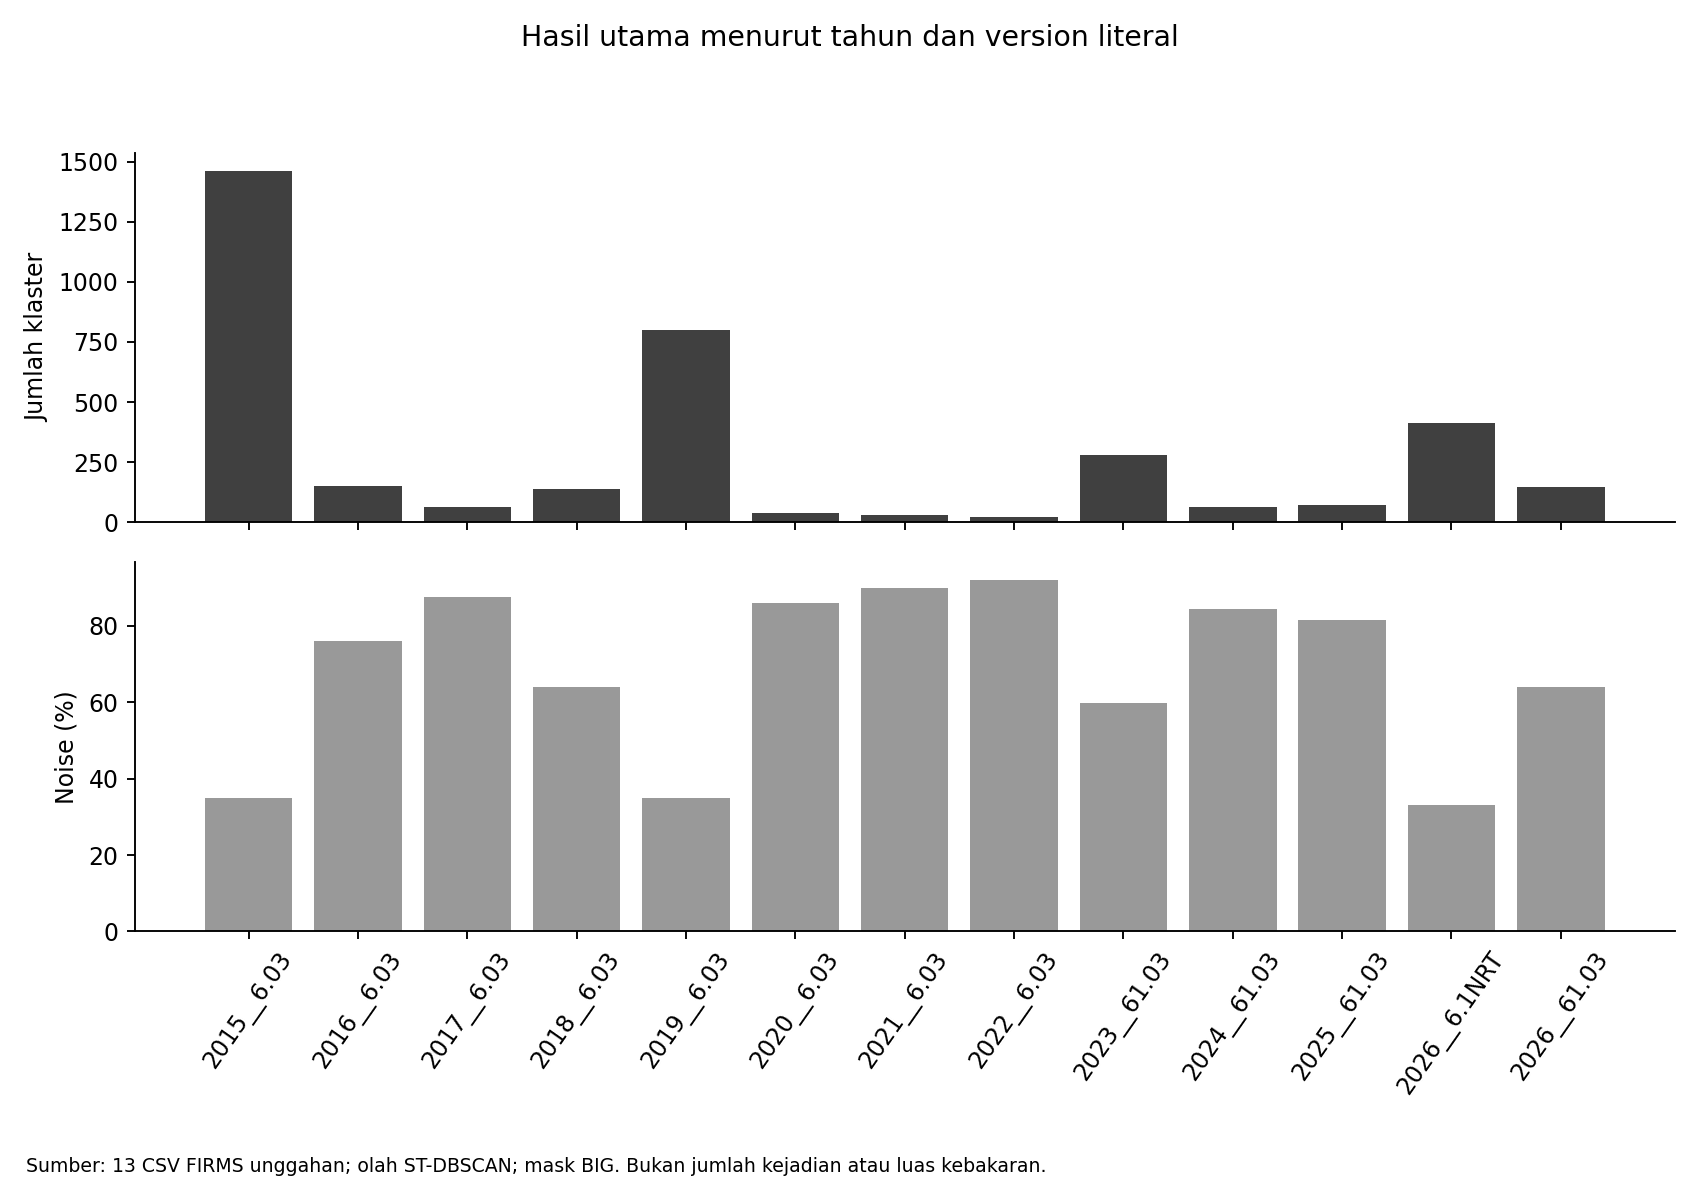

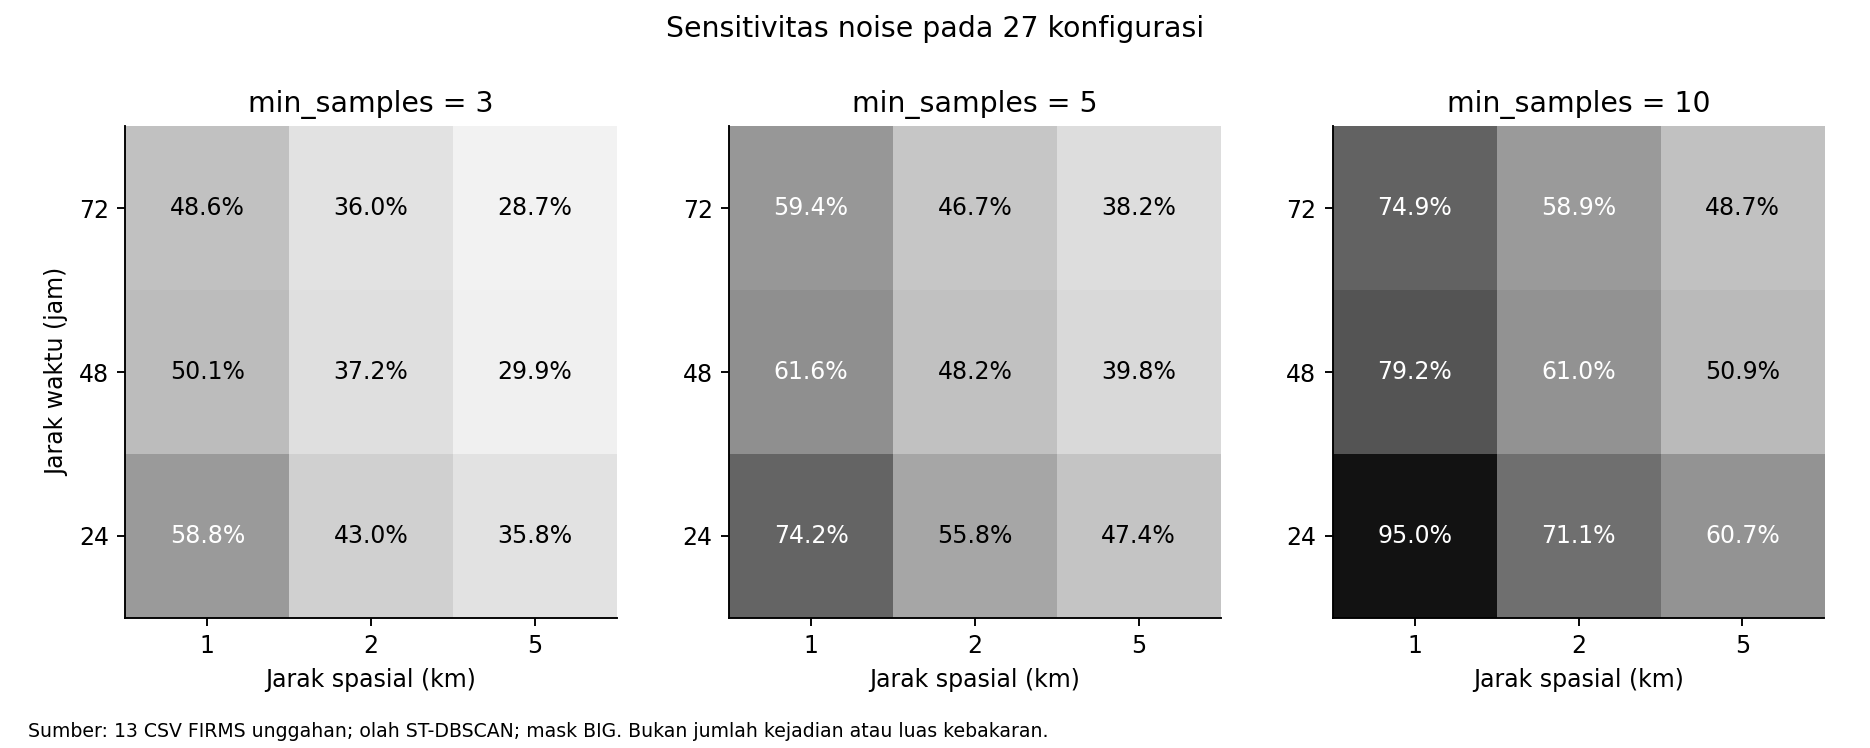

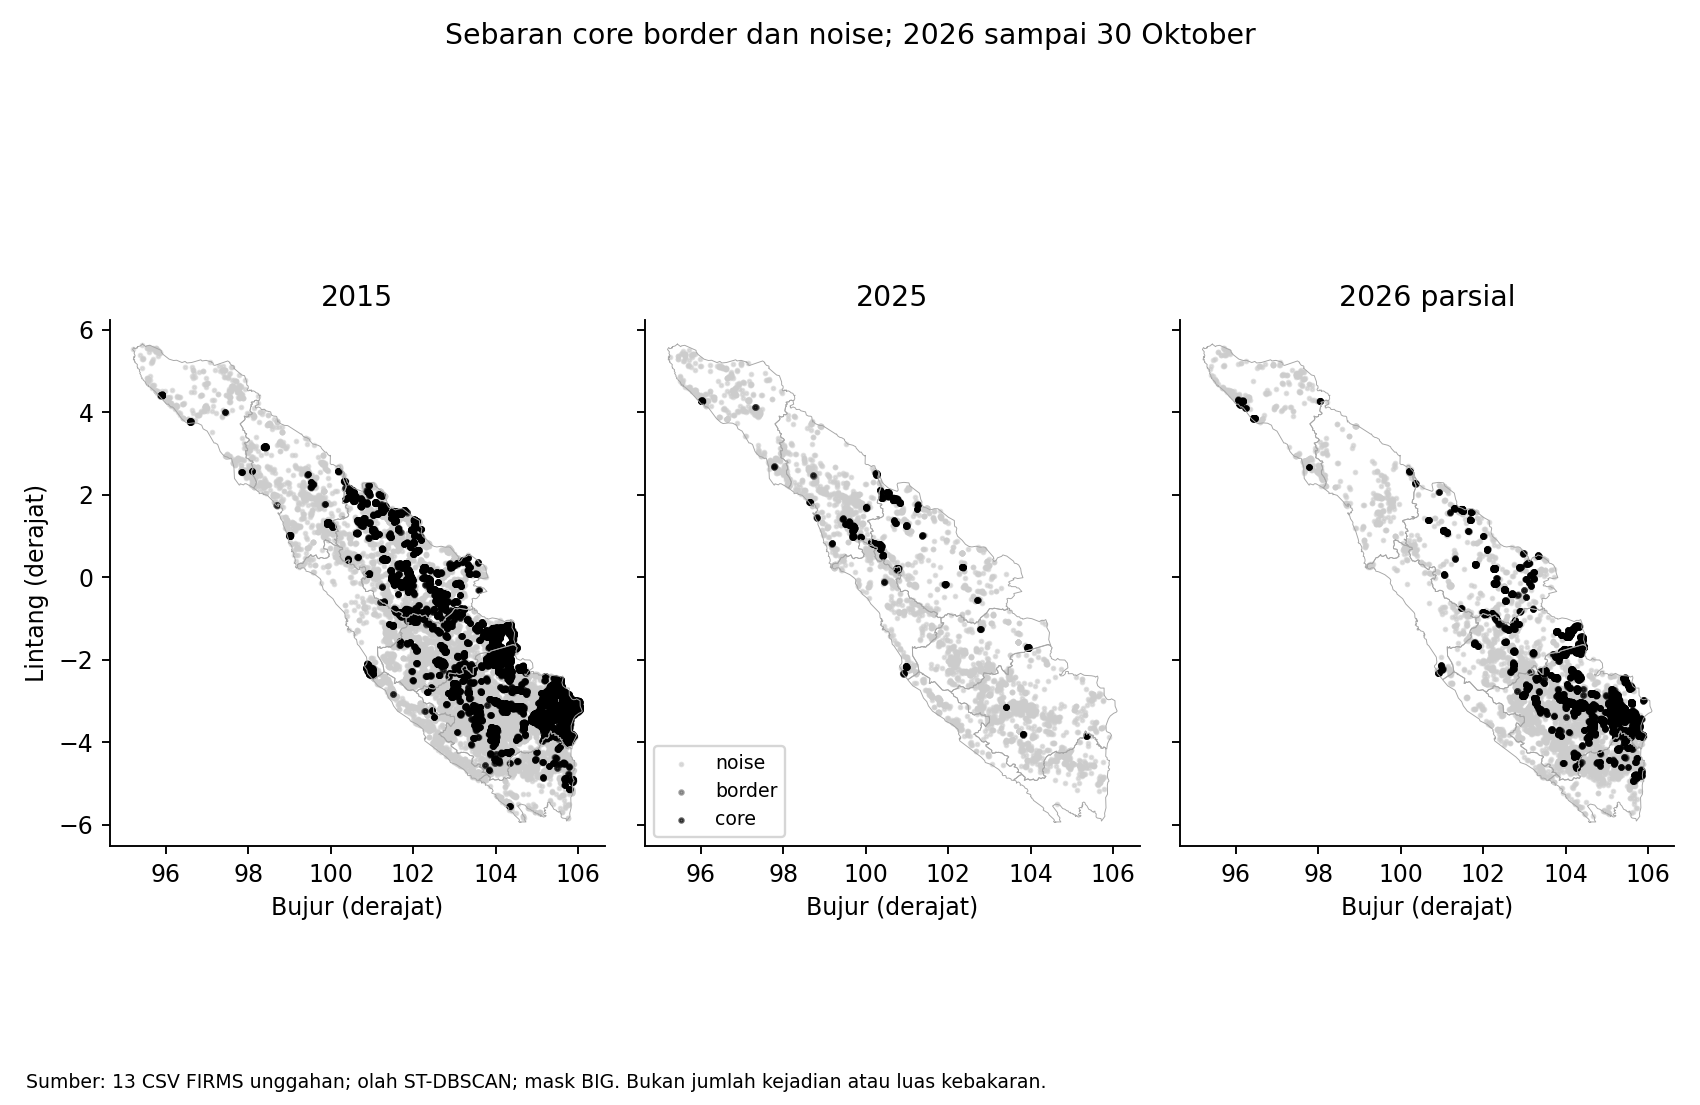

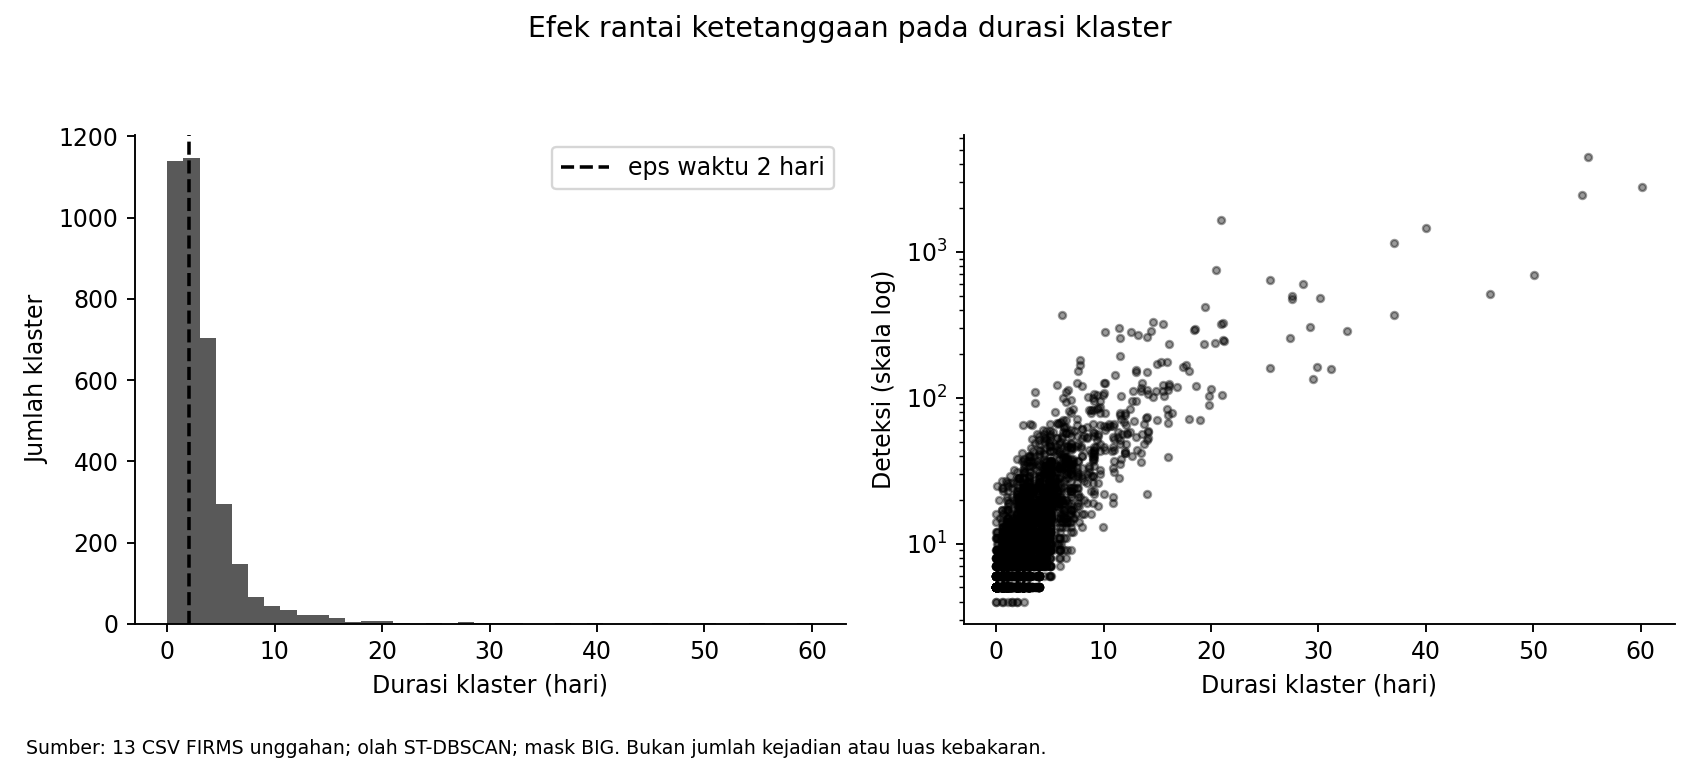

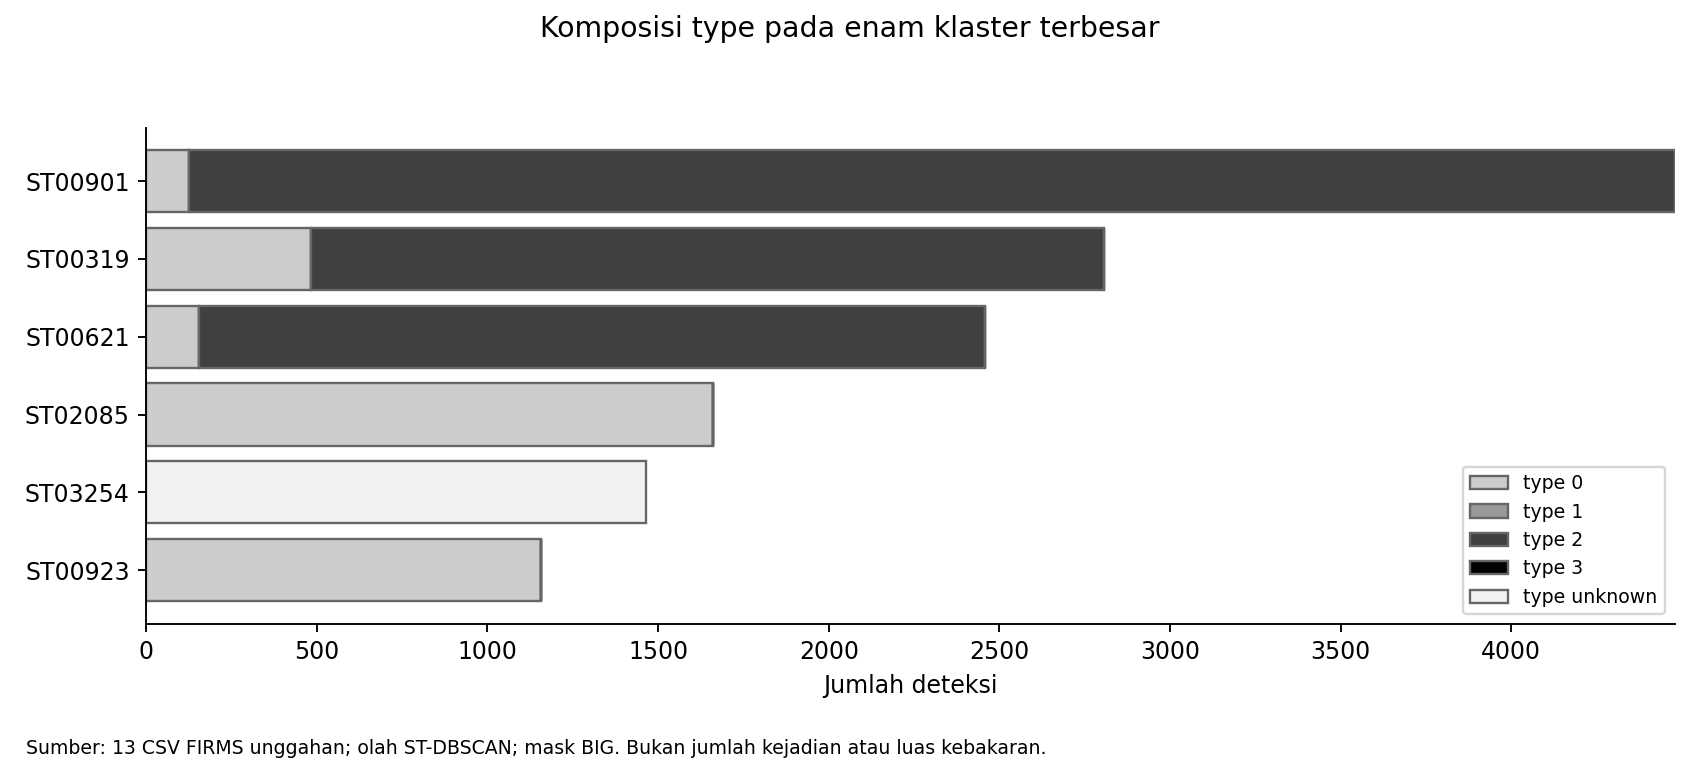

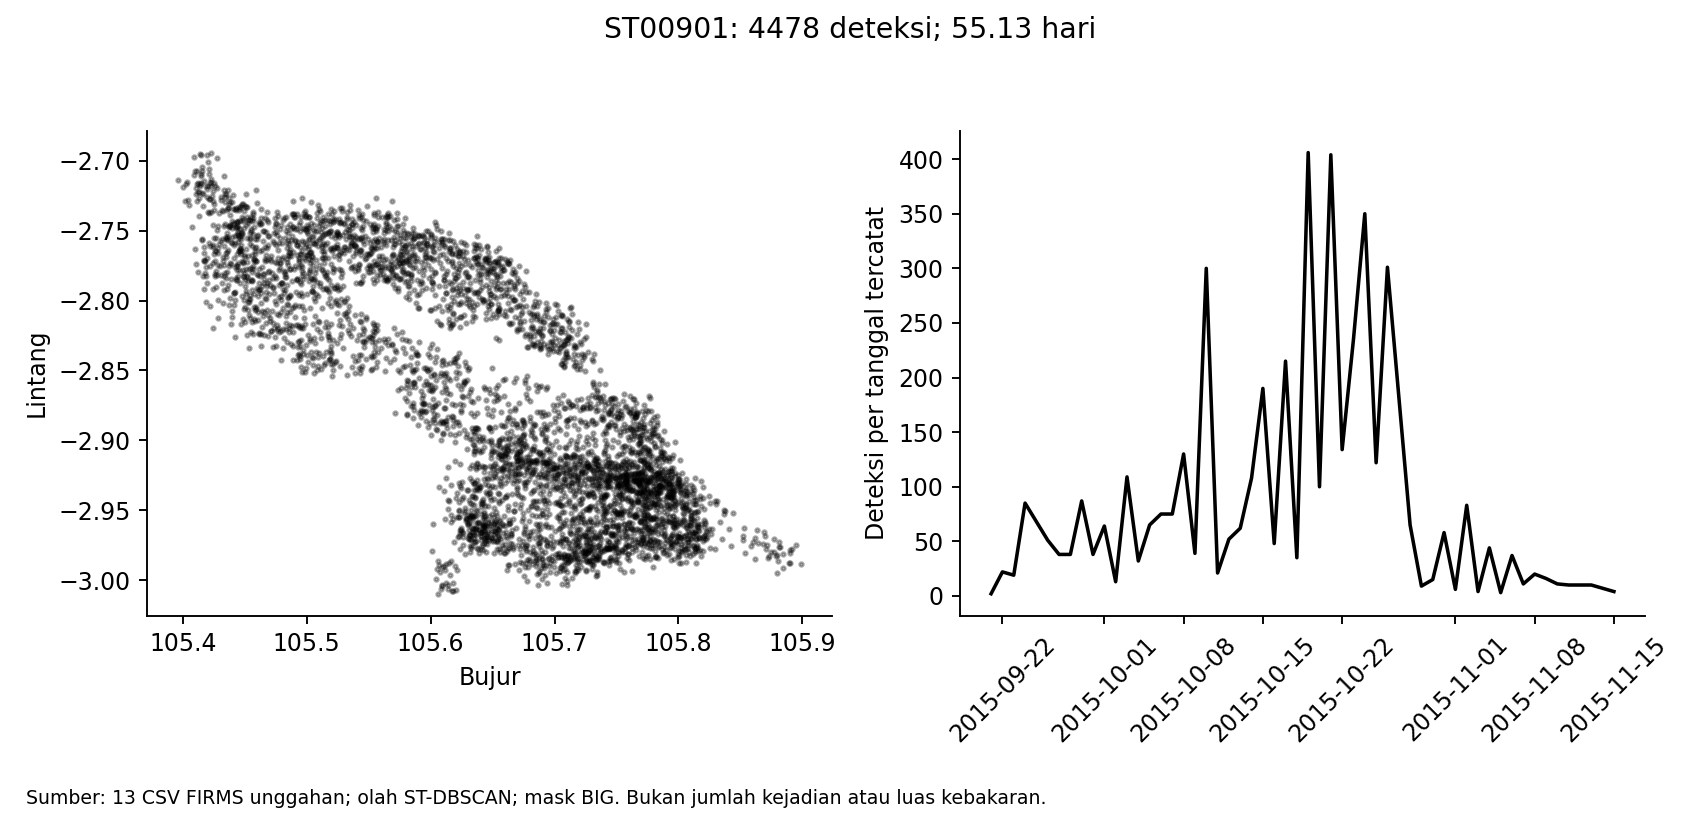

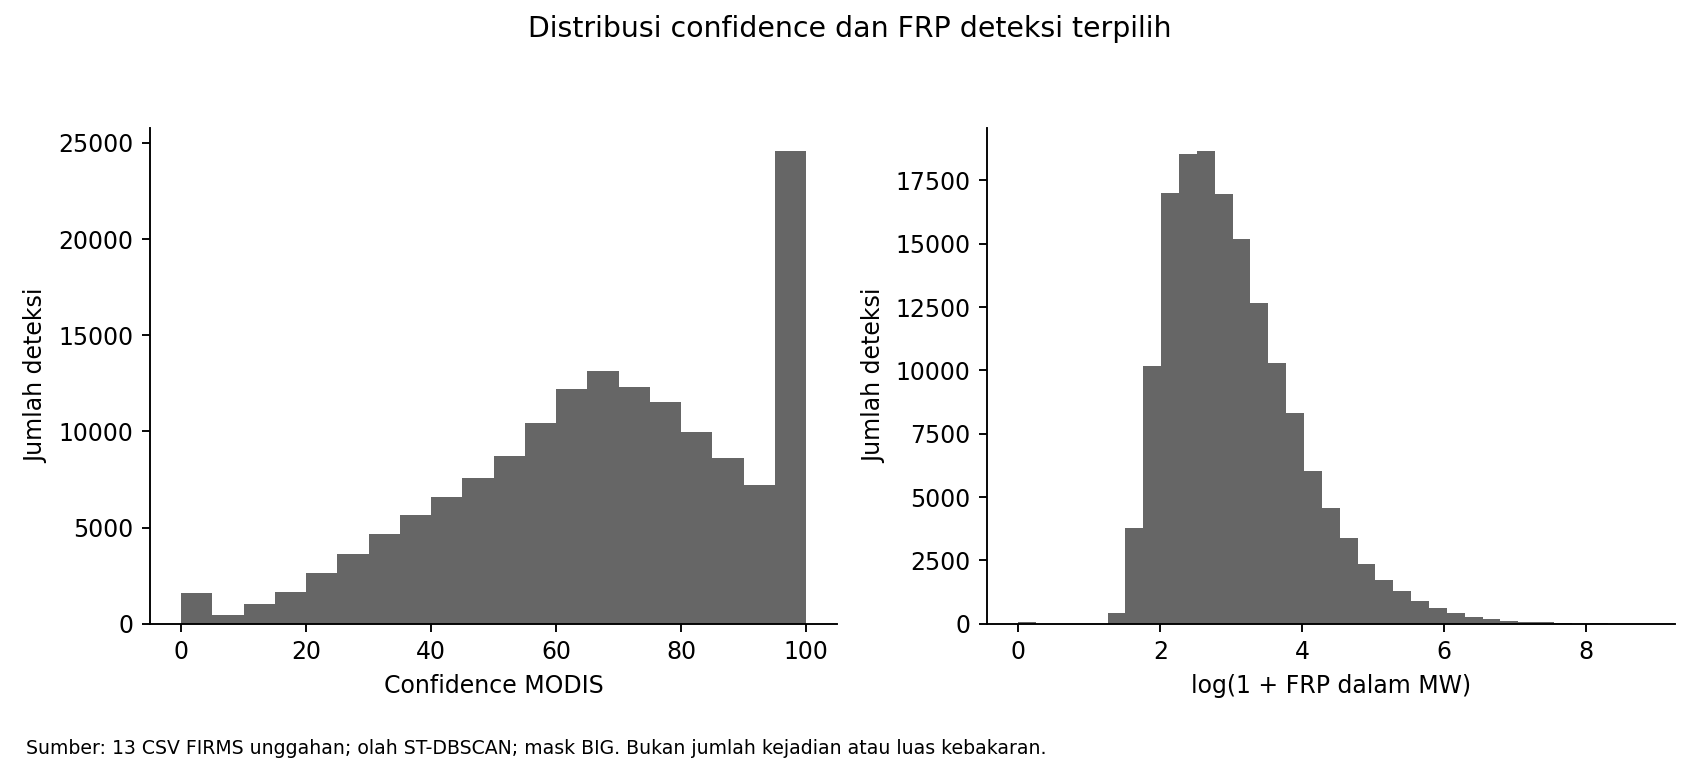

In [38]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use('Agg')
import matplotlib.pyplot as plt
from shapely.geometry import shape


def plot_all(base):
    base = Path(base)
    out = base / 'clustering/grafik'
    out.mkdir(exist_ok=True)
    a = pd.read_csv(
        base / 'clustering/hasil_st_dbscan.csv', dtype={'version': str, 'type': str}
    )
    s = pd.read_csv(base / 'clustering/sensitivitas_27_skenario.csv')
    c = pd.read_csv(base / 'clustering/ringkasan_klaster.csv')
    p = pd.read_csv(base / 'clustering/hasil_utama_per_strata.csv')
    plt.rcParams.update(
        {'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False}
    )
    source = 'Sumber: 13 CSV FIRMS unggahan; olah ST-DBSCAN; mask BIG. Bukan jumlah kejadian atau luas kebakaran.'

    def save(fig, name, title):
        fig.suptitle(title)
        fig.text(0.015, 0.015, source, fontsize=8)
        # Reserve extra bottom space for square heatmaps and their x-axis labels.
        bottom = 0.14 if name == '02_sensitivitas_noise.png' else 0.055
        fig.tight_layout(rect=[0, bottom, 1, 0.94])
        fig.savefig(out / name, dpi=170)
        plt.close(fig)

    fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    ax[0].bar(p.partition, p.clusters, color='.25')
    ax[0].set_ylabel('Jumlah klaster')
    ax[1].bar(p.partition, p.noise_percent, color='.6')
    ax[1].set_ylabel('Noise (%)')
    ax[1].tick_params(axis='x', rotation=55)
    save(
        fig,
        '01_klaster_noise_per_strata.png',
        'Hasil utama menurut tahun dan version literal',
    )
    fig, axes = plt.subplots(1, 3, figsize=(11, 4.4))
    for ax, m in zip(axes, [3, 5, 10]):
        mat = (
            s[s.min_samples.eq(m)]
            .pivot(
                index='eps_temporal_hours',
                columns='eps_spatial_km',
                values='noise_percent',
            )
            .sort_index()
        )
        ax.imshow(mat, origin='lower', cmap='Greys', vmin=20, vmax=100)
        ax.set_xticks(range(3), [1, 2, 5])
        ax.set_yticks(range(3), [24, 48, 72])
        ax.set_title(f'min_samples = {m}')
        ax.set_xlabel('Jarak spasial (km)')
        for i in range(3):
            for j in range(3):
                ax.text(
                    j,
                    i,
                    f'{mat.iloc[i,j]:.1f}%',
                    ha='center',
                    va='center',
                    color='white' if mat.iloc[i, j] > 58 else 'black',
                )
    axes[0].set_ylabel('Jarak waktu (jam)')
    save(fig, '02_sensitivitas_noise.png', 'Sensitivitas noise pada 27 konfigurasi')
    geo = json.loads((base / 'hasil/sumatera_daratan_utama.geojson').read_text())
    fig, axes = plt.subplots(1, 3, figsize=(10, 6.5), sharex=True, sharey=True)
    for ax, year in zip(axes, [2015, 2025, 2026]):
        for feat in geo['features']:
            g = shape(feat['geometry']).simplify(0.01)
            parts = list(g.geoms) if g.geom_type == 'MultiPolygon' else [g]
            for x in parts:
                ax.plot(*x.exterior.xy, color='.65', lw=0.4)
        for role, color, size in [
            ('noise', '.8', 2),
            ('border', '.4', 3),
            ('core', 'black', 3),
        ]:
            b = a[(a.year == year) & a.point_role.eq(role)]
            ax.scatter(b.longitude, b.latitude, s=size, c=color, label=role, alpha=0.6)
        ax.set_aspect('equal')
        ax.set_title(str(year) + (' parsial' if year == 2026 else ''))
        ax.set_xlabel('Bujur (derajat)')
    axes[0].set_ylabel('Lintang (derajat)')
    axes[1].legend(loc='lower left', fontsize=8)
    save(
        fig,
        '03_peta_peran_titik.png',
        'Sebaran core border dan noise; 2026 sampai 30 Oktober',
    )
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
    axes[0].hist(c.duration_days, bins=40, color='.35')
    axes[0].axvline(2, ls='--', c='black', label='eps waktu 2 hari')
    axes[0].legend()
    axes[0].set_ylabel('Jumlah klaster')
    axes[1].scatter(c.duration_days, c.detections, s=9, c='black', alpha=0.4)
    axes[1].set_yscale('log')
    axes[1].set_ylabel('Deteksi (skala log)')
    for ax in axes:
        ax.set_xlabel('Durasi klaster (hari)')
    save(
        fig,
        '04_durasi_ukuran_klaster.png',
        'Efek rantai ketetanggaan pada durasi klaster',
    )
    top = c.nlargest(6, 'detections').iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    left = np.zeros(len(top))
    for key, color in [
        ('type_0', '.8'),
        ('type_1', '.6'),
        ('type_2', '.25'),
        ('type_3', 'black'),
        ('type_unknown', '.95'),
    ]:
        ax.barh(
            top.cluster_id,
            top[key],
            left=left,
            color=color,
            edgecolor='.4',
            label=key.replace('_', ' '),
        )
        left += top[key]
    ax.set_xlabel('Jumlah deteksi')
    ax.legend(loc='lower right', fontsize=8)
    save(
        fig, '05_type_klaster_terbesar.png', 'Komposisi type pada enam klaster terbesar'
    )
    big = c.nlargest(1, 'detections').iloc[0]
    b = a[a.cluster_id.eq(big.cluster_id)]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
    axes[0].scatter(b.longitude, b.latitude, s=3, c='black', alpha=0.3)
    axes[0].set_xlabel('Bujur')
    axes[0].set_ylabel('Lintang')
    t = b.groupby('acq_date').size()
    axes[1].plot(pd.to_datetime(t.index), t.values, c='black')
    axes[1].tick_params(axis='x', rotation=45)
    axes[1].set_ylabel('Deteksi per tanggal tercatat')
    save(
        fig,
        '06_rincian_klaster_terbesar.png',
        f'{big.cluster_id}: {big.detections} deteksi; {big.duration_days:.2f} hari',
    )
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
    axes[0].hist(a.confidence, bins=20, color='.4')
    axes[0].set_xlabel('Confidence MODIS')
    axes[1].hist(np.log1p(a.frp), bins=35, color='.4')
    axes[1].set_xlabel('log(1 + FRP dalam MW)')
    for ax in axes:
        ax.set_ylabel('Jumlah deteksi')
    save(
        fig,
        '07_distribusi_confidence_frp.png',
        'Distribusi confidence dan FRP deteksi terpilih',
    )
    return out


plot_all(BASE)
from IPython.display import Image, display

for image_path in sorted((BASE / 'clustering/grafik').glob('*.png')):
    display(Image(filename=str(image_path)))

### 11. Geografi dan 2026 provisional
**Apa:** Membaca klaster terbesar dan jendela waktu sebanding.

**Mengapa:** Sumber statis dan NRT tanpa type membatasi klaim.

**Cara membaca:** Centroid bukan asal api; durasi panjang dapat berasal dari chaining. 2026 bukan setahun penuh.

In [39]:
display(clusters.nlargest(10, 'detections'))
display(pd.read_csv(BASE / 'hasil/tabel/perbandingan_1Jan_30Okt.csv'))

,cluster_id,partition,detections,start_utc,end_utc,duration_days,centroid_latitude,centroid_longitude,max_radius_km,dominant_province,provinces,confidence_mean,frp_mean_MW,frp_max_MW,near_boundary_n,type_0,type_1,type_2,type_3,type_unknown
901,ST00901,2015__6.03,4478,2015-09-21 15:06:00+00:00,2015-11-15 18:10:00+00:00,55.127778,-2.873538,105.650512,33.343091,Sumatera Selatan,Sumatera Selatan,84.211702,161.489661,6504.80,0,127,0,4351,0,0
319,ST00319,2015__6.03,2806,2015-08-11 15:13:00+00:00,2015-10-10 18:34:00+00:00,60.139583,-1.961058,103.990305,25.442093,Sumatera Selatan,Sumatera Selatan,77.898076,62.926087,1809.90,0,482,0,2324,0,0
621,ST00621,2015__6.03,2459,2015-09-04 06:36:00+00:00,2015-10-28 18:22:00+00:00,54.490278,-2.643286,105.465161,18.932022,Sumatera Selatan,Sumatera Selatan,81.230988,118.906669,4552.20,0,155,0,2304,0,0
2085,ST02085,2019__6.03,1661,2019-09-07 18:09:00+00:00,2019-09-28 15:30:00+00:00,20.889583,-1.643539,104.013463,17.696872,Jambi,Jambi;Sumatera Selatan,82.609272,179.175015,6647.60,0,1661,0,0,0,0
3254,ST03254,2026__6.1NRT,1464,2026-09-14 13:53:00+00:00,2026-10-24 13:42:00+00:00,39.992361,-3.367052,105.202114,15.882259,Sumatera Selatan,Sumatera Selatan,76.832650,48.501633,1825.93,0,0,0,0,0,1464
923,ST00923,2015__6.03,1158,2015-09-22 06:23:00+00:00,2015-10-29 06:42:00+00:00,37.013194,-3.386256,105.638744,15.651731,Sumatera Selatan,Sumatera Selatan,79.346287,90.909499,1525.50,0,1158,0,0,0,0
2035,ST02035,2019__6.03,746,2019-08-30 03:40:00+00:00,2019-09-19 15:37:00+00:00,20.497917,-1.307747,103.920218,19.232138,Jambi,Jambi,79.434316,82.070107,1022.10,0,746,0,0,0,0
324,ST00324,2015__6.03,697,2015-08-14 15:44:00+00:00,2015-10-03 18:28:00+00:00,50.113889,-1.601248,103.968925,10.859292,Jambi,Jambi,76.773314,63.992109,2490.90,0,69,0,628,0,0
393,ST00393,2015__6.03,642,2015-08-23 06:11:00+00:00,2015-09-17 18:28:00+00:00,25.511806,-3.311850,104.996068,9.688162,Sumatera Selatan,Sumatera Selatan,83.102804,83.770561,697.60,0,2,0,640,0,0
2087,ST02087,2019__6.03,600,2019-09-07 18:09:00+00:00,2019-10-06 06:54:00+00:00,28.531250,-1.497215,104.050827,13.852561,Jambi,Jambi,79.416667,78.159333,2059.90,0,600,0,0,0,0


,year,detections,dates_with_rows,confidence_mean,frp_mean_MW,frp_median_MW,nrt_rows,type_missing
0,2024,4268,236,61.898313,20.716682,12.10,0,0
1,2025,4203,207,65.363788,21.352106,11.90,0,0
2,2026,20252,255,71.121025,30.655248,15.21,14281,14281


### 12. Perhitungan manual
**Apa:** Memperlihatkan paling banyak 10 tetangga nyata dan hitungan CART terdahulu.

**Mengapa:** Dosen dapat menelusuri row_id.

**Cara membaca:** Tetangga berlaku pada sampel validasi, bukan seluruh data. CART memakai type asli sebagai latihan, bukan label lonjakan.

In [40]:
display(pd.read_csv(BASE / 'clustering/contoh_manual_tetangga_nyata.csv'))
display(pd.read_csv(BASE / 'hasil/contoh_manual_10_baris.csv'))
display(pd.Series(json.loads((BASE / 'hasil/perhitungan_manual.json').read_text())))

,anchor_row_id,row_id,latitude,longitude,acq_datetime_utc,distance_km,time_difference_hours,anchor_total_neighbors_including_self
0,fire_archive_M-C61_834980.csv:L47211,fire_archive_M-C61_834980.csv:L47211,-2.2894,104.0552,2015-09-01 06:05:00+00:00,0.000000,0.000000,10
1,fire_archive_M-C61_834980.csv:L47211,fire_archive_M-C61_834980.csv:L47216,-2.2951,104.0517,2015-09-01 06:05:00+00:00,0.743598,0.000000,10
2,fire_archive_M-C61_834980.csv:L47211,fire_archive_M-C61_834980.csv:L47987,-2.2932,104.0547,2015-09-01 15:31:00+00:00,0.426178,9.433333,10
3,fire_archive_M-C61_834980.csv:L47211,fire_archive_M-C61_834980.csv:L47989,-2.2829,104.0626,2015-09-01 15:31:00+00:00,1.094709,9.433333,10
4,fire_archive_M-C61_834980.csv:L47211,fire_archive_M-C61_834980.csv:L47990,-2.2841,104.0534,2015-09-01 15:31:00+00:00,0.622343,9.433333,10
5,fire_archive_M-C61_834980.csv:L47211,fire_archive_M-C61_834980.csv:L47991,-2.2854,104.0443,2015-09-01 15:31:00+00:00,1.290154,9.433333,10
6,fire_archive_M-C61_834980.csv:L47211,fire_archive_M-C61_834980.csv:L47994,-2.2752,104.0551,2015-09-01 15:31:00+00:00,1.579009,9.433333,10
7,fire_archive_M-C61_834980.csv:L47211,fire_archive_M-C61_834980.csv:L48887,-2.2807,104.0578,2015-09-01 18:28:00+00:00,1.009608,12.383333,10
8,fire_archive_M-C61_834980.csv:L47211,fire_archive_M-C61_834980.csv:L49285,-2.2865,104.0535,2015-09-02 03:54:00+00:00,0.373711,21.816667,10
9,fire_archive_M-C61_834980.csv:L47211,fire_archive_M-C61_834980.csv:L49793,-2.2866,104.0623,2015-09-02 06:48:00+00:00,0.848074,24.716667,10


,row_id,source_file,source_row,acq_date,acq_time,province,latitude,longitude,confidence,frp,type
0,fire_archive_M-C61_834980.csv:L18,fire_archive_M-C61_834980.csv,18,2015-01-02,322,Sumatera Utara,1.1195,98.9519,27,28.5,0
1,fire_archive_M-C61_834980.csv:L25,fire_archive_M-C61_834980.csv,25,2015-01-03,405,Sumatera Barat,-0.7324,100.8091,80,48.1,0
2,fire_archive_M-C61_834980.csv:L26,fire_archive_M-C61_834980.csv,26,2015-01-03,405,Sumatera Barat,-0.7329,100.8189,75,38.0,0
3,fire_archive_M-C61_834980.csv:L27,fire_archive_M-C61_834980.csv,27,2015-01-03,405,Sumatera Barat,-0.7307,100.8037,61,23.3,0
4,fire_archive_M-C61_834980.csv:L30,fire_archive_M-C61_834980.csv,30,2015-01-03,1922,Sumatera Utara,3.1592,98.4033,50,17.9,1
5,fire_archive_M-C61_834980.csv:L31,fire_archive_M-C61_834980.csv,31,2015-01-03,1922,Sumatera Utara,3.1708,98.4030,69,18.8,1
6,fire_archive_M-C61_834980.csv:L39,fire_archive_M-C61_834980.csv,39,2015-01-05,648,Sumatera Selatan,-3.0357,105.3081,50,10.1,0
7,fire_archive_M-C61_834980.csv:L40,fire_archive_M-C61_834980.csv,40,2015-01-05,649,Sumatera Barat,-1.3993,101.6722,92,40.1,0
8,fire_archive_M-C61_834980.csv:L41,fire_archive_M-C61_834980.csv,41,2015-01-05,649,Sumatera Barat,-1.3630,101.4056,80,15.7,0
9,fire_archive_M-C61_834980.csv:L42,fire_archive_M-C61_834980.csv,42,2015-01-05,649,Sumatera Barat,-1.3477,101.4490,71,8.4,0


purpose                   Latihan CART pada type asli; BUKAN hasil klasi...
selection                 10 deteksi pertama daratan utama Sumatera tahu...
n                                                                        10
class_counts                                               {'0': 8, '1': 2}
split_attribute                                                  confidence
split_threshold                                                        70.0
parent_entropy_bits                                                0.721928
parent_gini                                                            0.32
left_n                                                                    5
left_counts                                                {'0': 3, '1': 2}
right_n                                                                   5
right_counts                                                       {'0': 5}
weighted_child_entropy                                             0.485475
information_

### 13. Audit akhir
**Apa:** Memastikan keunikan ID, cutoff dan tidak ada classifier.

**Mengapa:** Keluaran harus sesuai status ilmiah.

**Cara membaca:** Classification tetap BELUM MEMENUHI. Run All berhasil tidak berarti label telah sah.

In [ ]:
assert not gate['classification_feasible'] and not gate['model_fitted']
assert len(result) == 154184 and result.row_id.is_unique
assert result.acq_datetime_utc.max() <= CUTOFF
assert set(result.point_role) == {'core', 'border', 'noise'}
save_json(
    BASE / 'clustering/assertions_revisi.json',
    dict(
        raw_hash_preserved=True,
        unique_row_ids=True,
        cutoff_respected=True,
        no_classifier_fit=True,
        no_negative_labels_fabricated=True,
    ),
)
print('Audit dan clustering selesai; classification BELUM MEMENUHI Karena data tahun 2026 belum selesai dikarenakan dan data belum tersedia.')
print('Waktu proses detik:', round(time.monotonic() - START, 2))

Audit dan clustering selesai; classification BELUM MEMENUHI.
Waktu proses detik: 103.54


### Sumber
Tujuh materi dosen/e-learning: lihat manifest_materi.csv dan peta_kesesuaian_materi.csv.

Giglio, L., Schroeder, W., Hall, J. V., & Justice, C. O. (2021). *MODIS Collection 6 and Collection 6.1 Active Fire Product User’s Guide* (V1.0). https://lpdaac.usgs.gov/documents/1005/MOD14_User_Guide_V61.pdf

Birant, D., & Kut, A. (2007). ST-DBSCAN: An algorithm for clustering spatial–temporal data. *Data & Knowledge Engineering,60*(1),208–221. https://doi.org/10.1016/j.datak.2006.01.013 . Metadata/abstrak; seluruh ekstensi tidak diklaim direplikasi.

Cakmak, E., & Plank, M. (n.d.). *st_dbscan* [Kode MIT]. https://github.com/eren-ck/st_dbscan

scikit-learn developers. (n.d.). *DBSCAN; Clustering*. https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html ; https://scikit-learn.org/stable/modules/clustering.html

NASA GIBS. (n.d.). *Accessing via Python*. https://nasa-gibs.github.io/gibs-api-docs/python-usage/

BIG. (n.d.). *Batas Administrasi Provinsi*. https://geoservices.big.go.id/gis/rest/services/STIG/Batas_Provinsi/MapServer/0
